In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import random
import numpy as np
import pandas as pd
import scanpy as sc
import torch
import spice

from simulate_xenium import simulate_xenium

In [4]:
sc.set_figure_params(frameon=False)

In [5]:
def set_seeds(seed: int) -> None:
    """Seed all random-state sources for fully reproducible GNN training.

    Covers: Python random, NumPy global state, PyTorch CPU/CUDA, and
    cuDNN determinism flags.  Call once at notebook start and once per
    simulation iteration to reset the state before each training run.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

## Run SPiCe

## 10-run simulation benchmark

In [6]:
EMT_MAP = {0: "Epi", 1: "H-Epi", 2: "H-Mes", 3: "Mes"}

all_aucs = []

random.seed(0)
reproducible_seeds = [random.randint(0, 2**16 - 1) for _ in range(100)]

for seed in reproducible_seeds:
    print(f"Running simulation with seed {seed}...\n")
    adata_s, _ = simulate_xenium(seed=seed)

    valid_states = {
        "Epi": 0,
        "H-Epi": 1,
        "H-Mes": 2,
        "Mes": 3,
    }
    adata_s.obs["state_label"] = (adata_s.obs["cell_type"].map(valid_states).fillna(-1).astype(int))
    adata_s.obs["state_label"] = adata_s.obs["state_label"].astype("category")
    adata_s.obs["state_label"] = adata_s.obs["state_label"].cat.remove_unused_categories()

    spice.tl.build_graph(
        adata_s,
        celltype_key="celltype_minor",
        label_key="state_label",
        score_key=None,
        n_blocks=8
    )

    spice.tl.cross_validate(adata_s, feature_mode="celltype")
    spice.tl.evaluate(adata_s)

    auc_df = adata_s.uns["spice"]["auc"].copy()
    auc_df["sample"] = f"sim_{seed:02d}"
    all_aucs.append(auc_df)

combined_auc = pd.concat(all_aucs, ignore_index=True)
print(f"\nDone. Total AUC records: {len(combined_auc)}")

Running simulation with seed 50494...




Fold 1/5


  Epoch    0 | Loss 0.3146 | Test AUC: 0.5936


  Epoch  100 | Loss 0.2348 | Test AUC: 0.7931


  Epoch  200 | Loss 0.2278 | Test AUC: 0.7995


  Epoch  300 | Loss 0.2279 | Test AUC: 0.8016


... (2,868 outputs left out)

  Epoch  200 | Loss 0.2343 | Test AUC: 0.7424


  Epoch  300 | Loss 0.2307 | Test AUC: 0.7458


  Epoch  400 | Loss 0.2304 | Test AUC: 0.7438


  Epoch  499 | Loss 0.2290 | Test AUC: 0.7406

Mean performance: 0.7706 ± 0.0181

Done. Total AUC records: 3000


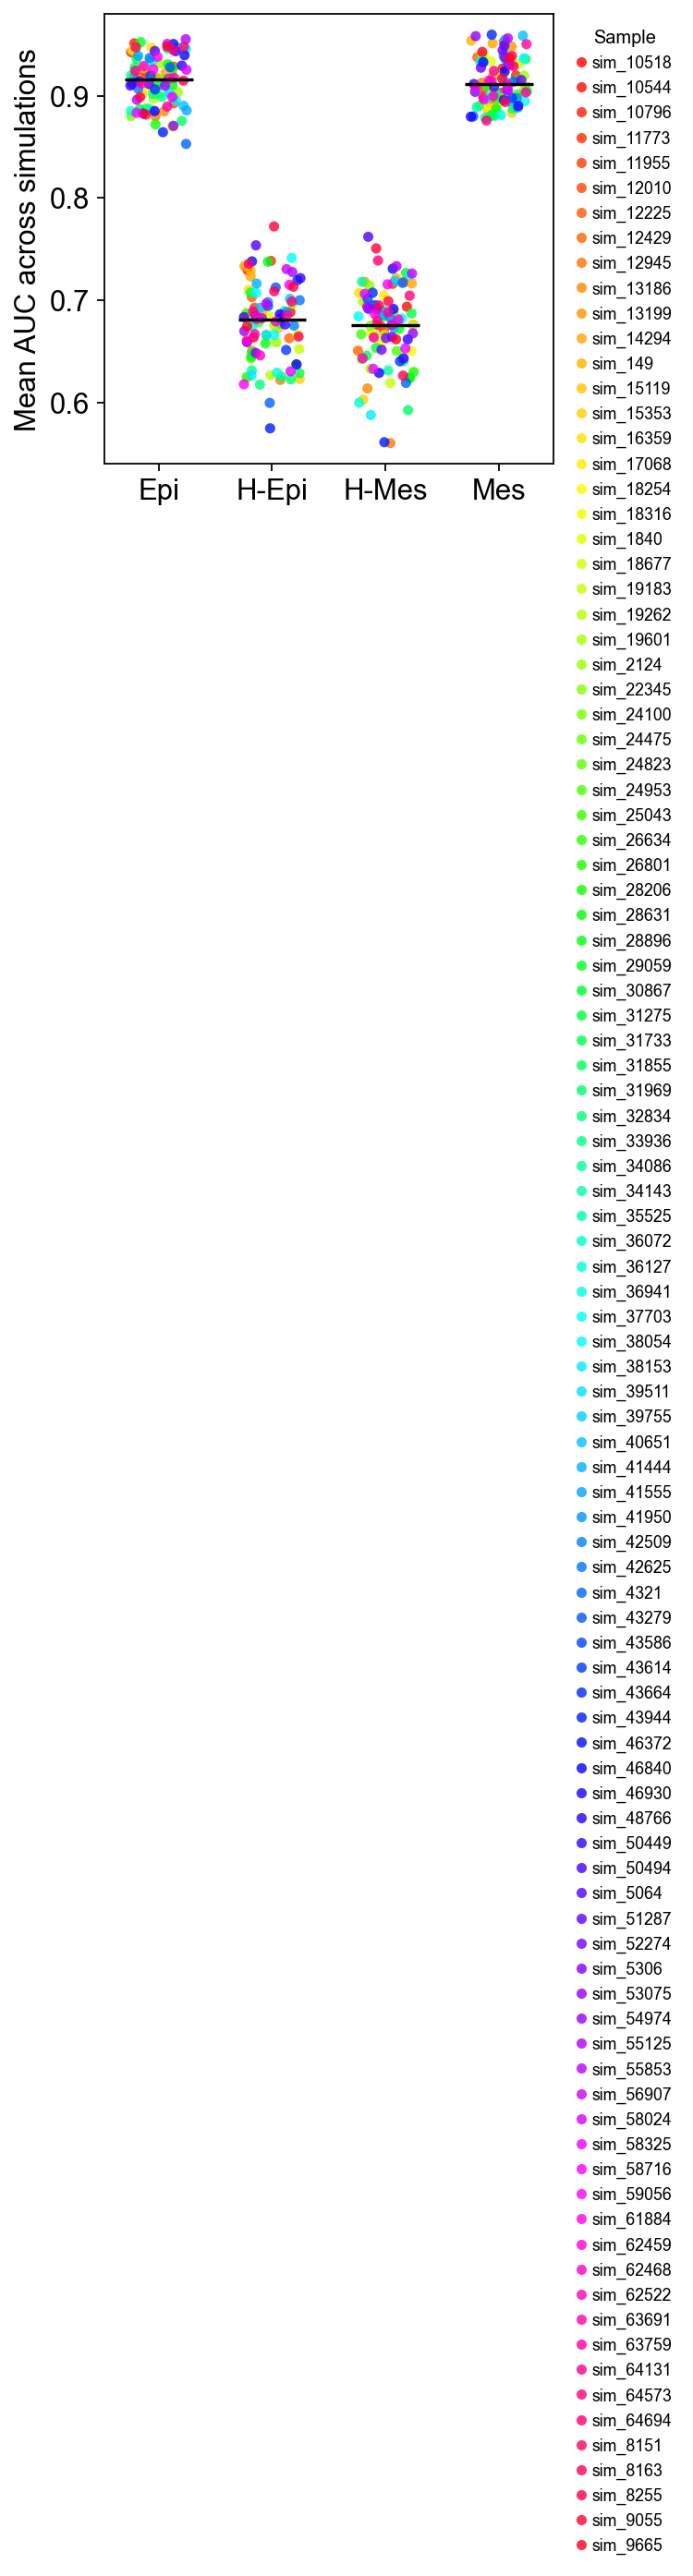

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Average AUC across simulations for each sample × EMT state
per_class = combined_auc[combined_auc["class"].str.isdigit()].copy()
per_class["state"] = per_class["class"].astype(int).map(EMT_MAP)

order = [EMT_MAP[k] for k in sorted(EMT_MAP.keys())]

# Assumes there is a column identifying simulation/run
# e.g. "simulation", "run", or similar.
SIM_COL = "class"

per_class_mean = per_class.groupby(["sample", "state", SIM_COL], as_index=False)["AUC"].mean()

# Colours
palette = {
    s: plt.cm.hsv(i)
    for s, i in zip(
        sorted(per_class_mean["sample"].unique()),
        np.linspace(0, 1, per_class_mean["sample"].nunique(), endpoint=False),
    )
}

# Plot
fig, ax = plt.subplots(figsize=(6, 4))

sns.stripplot(
    data=per_class_mean,
    x="state",
    y="AUC",
    hue="sample",
    order=order,
    palette=palette,
    jitter=0.25,
    dodge=False,
    size=5,
    alpha=0.8,
    ax=ax,
)

# Median bars per EMT state
median = per_class_mean.groupby("state")["AUC"].median()

for i, state in enumerate(order):
    if state in median.index:
        ax.hlines(
            median[state],
            i - 0.3,
            i + 0.3,
            colors="black",
            linewidth=1.5,
            zorder=10,
        )

# Formatting
ax.set_ylabel("Mean AUC across simulations")
ax.set_xlabel("")
ax.set_box_aspect(1)

ax.legend(
    title="Sample",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    title_fontsize=9,
    frameon=False,
)

plt.grid(False)
plt.tight_layout()
plt.savefig(
    "figures/simulated_auc_per_class_mean_across_simulations.pdf",
    bbox_inches="tight",
)
plt.show()